# Notebook 1: Motion-robust heart rate from wrist PPG (PPG-DaLiA)

**Goal of this notebook:** load the data, cut it into windows, and build two
simple heart-rate estimators so you can *see* how motion breaks the signal and
how much the accelerometer trick helps.

| Method | Idea in plain words |
|---|---|
| **A. Naive** | Take the strongest rhythm in the PPG signal and call it the heart rate. |
| **B. Motion-aware** | Same, but turn down the PPG "volume" at frequencies where the accelerometer says the body is moving. |

No machine learning yet. Notebook 2 improves the estimator further (it stays near the
previous estimate) and notebooks 3 and 4 add a quality model on top.

In [9]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks

## 0. Settings
Set `DATA_ROOT` to the folder where you unzipped PPG-DaLiA. The code searches
inside it for `S1.pkl`, `S2.pkl`, ... so the exact sub-folder layout doesn't matter.

Set `MAKE_FAKE = True` for a **dry run** with made-up data (to check the code runs
before you download 2.7 GB). Numbers from fake data mean nothing.

In [10]:
DATA_ROOT = r"C:\Users\diya0\Downloads\ppg+dalia\data\PPG_FieldStudy"           # folder where you unzipped PPG-DaLiA (searched recursively)
RESULTS_DIR = "results"
MAKE_FAKE = False                # True = dry run on synthetic data (writes to ../dryrun, never to ../results)
if MAKE_FAKE:
    DATA_ROOT, RESULTS_DIR = "../dryrun/fake_dalia", "../dryrun/results"

FS_PPG, FS_ACC, FS_ACT = 64, 32, 4   # sampling rates in Hz (PPG-DaLiA wrist device)
WIN_S, SHIFT_S = 8, 2                # 8-second windows, a new window every 2 seconds
F_LO, F_HI = 0.7, 3.5                # search band: 42 to 210 beats per minute
N_FFT = 4096                         # zero-padding: smoother spectrum, finer peak position
ALPHA = 0.9                          # how strongly to turn down motion frequencies

ACTIVITY_NAMES = {0: "transient", 1: "sitting", 2: "stairs", 3: "table soccer",
                  4: "cycling", 5: "driving", 6: "lunch break", 7: "walking", 8: "working"}
os.makedirs(RESULTS_DIR, exist_ok=True)

## Optional dry run: fake data in the same format as PPG-DaLiA
Only runs if `MAKE_FAKE = True`. It makes 3 fake people whose PPG is polluted by
their arm-swing, so you can check the whole pipeline end to end.

In [11]:
def make_fake_dataset(root, n_subjects=3, minutes=8, seed=0):
    rng = np.random.default_rng(seed)
    for sid in range(1, n_subjects + 1):
        secs = minutes * 60
        t = np.arange(secs * FS_PPG) / FS_PPG
        # true heart rate drifts slowly between 65 and 150 bpm
        hr_t = 105 + 40 * np.sin(2 * np.pi * t / 240 + sid) + 5 * np.sin(2 * np.pi * t / 37)
        phase = 2 * np.pi * np.cumsum(hr_t / 60) / FS_PPG
        # activity changes every 160 s: sitting(1) -> walking(7) -> cycling(4)
        act_t = np.repeat([1, 7, 4], secs // 3 * FS_ACT)[: secs * FS_ACT]
        act_t = np.pad(act_t, (0, secs * FS_ACT - len(act_t)), constant_values=4)
        moving = np.repeat(act_t != 1, FS_PPG // FS_ACT)[: len(t)]
        step_hz = 1.6 + 0.4 * np.sin(2 * np.pi * t / 90)
        step_phase = 2 * np.pi * np.cumsum(step_hz) / FS_PPG
        ppg = np.sin(phase) + 0.3 * np.sin(2 * phase)
        ppg = ppg + moving * 1.2 * np.sin(step_phase) + 0.2 * rng.standard_normal(len(t))
        acc = np.stack([moving * 30 * np.sin(step_phase + k) for k in range(3)], axis=1)
        acc = acc[:: FS_PPG // FS_ACC] + 1.5 * rng.standard_normal((secs * FS_ACC, 3))
        n_win = (secs - WIN_S) // SHIFT_S + 1
        label = np.array([hr_t[i * SHIFT_S * FS_PPG: (i * SHIFT_S + WIN_S) * FS_PPG].mean()
                          for i in range(n_win)])
        d = {"signal": {"wrist": {"BVP": ppg[:, None], "ACC": acc}},
             "label": label, "activity": act_t[:, None], "subject": f"S{sid}"}
        os.makedirs(os.path.join(root, f"S{sid}"), exist_ok=True)
        with open(os.path.join(root, f"S{sid}", f"S{sid}.pkl"), "wb") as f:
            pickle.dump(d, f, protocol=2)

if MAKE_FAKE:
    make_fake_dataset(DATA_ROOT)
    print("Fake dataset written to", DATA_ROOT)

## 1. Load one person's recording
Each subject file holds: wrist PPG (called BVP), wrist accelerometer (ACC), the true
heart rate per window (`label`, computed from a chest ECG), and what the person was doing.

In [12]:
def index_pkls(root):
    found = {}
    for dirpath, _, files in os.walk(root):
        for fn in files:
            if fn.startswith("S") and fn.endswith(".pkl"):
                try:
                    found[int(fn[1:-4])] = os.path.join(dirpath, fn)
                except ValueError:
                    pass
    return found

PKL = index_pkls(DATA_ROOT)
print("Subjects found:", sorted(PKL))
assert PKL, f"No S*.pkl files under '{DATA_ROOT}'. Check DATA_ROOT."

def load_subject(sid):
    with open(PKL[sid], "rb") as f:
        d = pickle.load(f, encoding="latin1")   # files were saved with old Python
    bvp = np.asarray(d["signal"]["wrist"]["BVP"], dtype=float).ravel()
    acc = np.asarray(d["signal"]["wrist"]["ACC"], dtype=float)      # (N, 3)
    hr = np.asarray(d["label"], dtype=float).ravel()
    act = np.asarray(d["activity"]).ravel().astype(int)
    return bvp, acc, hr, act

def inspect_subject(sid):
    bvp, acc, hr, act = load_subject(sid)
    n_ppg = (len(bvp) - WIN_S * FS_PPG) // (SHIFT_S * FS_PPG) + 1
    print(f"S{sid}: PPG {bvp.shape} = {len(bvp)/FS_PPG/60:.1f} min | ACC {acc.shape} | "
          f"HR labels {hr.shape} | activity {act.shape}")
    print(f"  windows expected from PPG length: {n_ppg}, labels given: {len(hr)} "
          f"(these should be about equal)")
    print("  HR label range:", hr.min().round(1), "to", hr.max().round(1), "bpm")

inspect_subject(sorted(PKL)[0])

Subjects found: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
S1: PPG (589568,) = 153.5 min | ACC (294784, 3) | HR labels (4603,) | activity (36848,)
  windows expected from PPG length: 4603, labels given: 4603 (these should be about equal)
  HR label range: 41.9 to 150.2 bpm


## 2. Clean and window the signals
* **Bandpass filter 0.5 to 4 Hz** keeps only rhythms between 30 and 240 beats per minute
  and removes slow drift (breathing, sweat, skin movement) and fast noise.
* **Windows:** 8 seconds of signal gives one heart-rate estimate; a new one every 2 seconds.
  This is the standard setup for this dataset.

Note: `sosfiltfilt` filters forwards and backwards, which peeks at the future.
That's fine for offline analysis, but a real device must filter in real time (causal).

In [13]:
def bandpass(x, fs, lo=0.5, hi=4.0, order=4):
    sos = butter(order, [lo, hi], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x)

def make_windows(bvp, acc, hr, act):
    wp, sp = WIN_S * FS_PPG, SHIFT_S * FS_PPG
    wa, sa = WIN_S * FS_ACC, SHIFT_S * FS_ACC
    n = min(len(hr), (len(bvp) - wp) // sp + 1, (len(acc) - wa) // sa + 1)
    ppg_w = np.stack([bvp[i * sp: i * sp + wp] for i in range(n)])
    acc_w = np.stack([acc[i * sa: i * sa + wa] for i in range(n)])      # (n, wa, 3)
    act_w = np.array([np.bincount(act[i * SHIFT_S * FS_ACT:(i * SHIFT_S + WIN_S) * FS_ACT]).argmax()
                      for i in range(n)])                                # most common activity
    return ppg_w, acc_w, hr[:n], act_w

## 3. Heart rate from the spectrum
A heartbeat is a repeating pattern. The **FFT** shows how strong each repeat-rate is.
The tallest bump in the 0.7 to 3.5 Hz range is usually the heart rate
(frequency in Hz x 60 = beats per minute).

**Problem:** running, cycling or swinging your arm is also a repeating pattern, and
it leaks into the PPG. Sometimes it is taller than the heartbeat bump.

**Trick (method B):** the accelerometer measures only body motion. Wherever the
accelerometer's spectrum is tall, we turn down the PPG spectrum. We do this more
strongly in windows where the person is moving a lot (`motion_level`, scaled per person).

In [14]:
FREQS = np.fft.rfftfreq(N_FFT, 1 / FS_PPG)
BAND = (FREQS >= F_LO) & (FREQS <= F_HI)
FB = FREQS[BAND]

def spectrum(x, fs, n_fft):
    x = (x - x.mean()) * np.hanning(len(x))
    return np.fft.rfftfreq(n_fft, 1 / fs), np.abs(np.fft.rfft(x, n=n_fft))

def acc_spectrum_on_grid(acc_win):
    n_fft = N_FFT * FS_ACC // FS_PPG
    total = 0
    for ax in range(3):
        fa, sa = spectrum(acc_win[:, ax], FS_ACC, n_fft)
        total = total + np.interp(FB, fa, sa)
    return total / (total.max() + 1e-12)          # 0..1: how "loud" motion is at each frequency

def top_peaks(sp, k=3):
    idx, _ = find_peaks(sp)
    if len(idx) == 0:
        return [int(np.argmax(sp))]
    return list(idx[np.argsort(sp[idx])[::-1]][:k])

def run_methods(ppg_w, acc_w, motion_level):
    n = len(ppg_w)
    est_a, est_b = np.zeros(n), np.zeros(n)
    for i in range(n):
        _, s = spectrum(ppg_w[i], FS_PPG, N_FFT)
        s = s[BAND]
        # A: naive
        est_a[i] = 60 * FB[np.argmax(s)]
        # B: turn down the volume where the accelerometer is loud
        s_b = s * (1 - ALPHA * motion_level[i] * acc_spectrum_on_grid(acc_w[i]))
        est_b[i] = 60 * FB[top_peaks(s_b)[0]]
    return est_a, est_b

def process_subject(sid):
    bvp, acc, hr, act = load_subject(sid)
    bvp_f = bandpass(bvp, FS_PPG)
    acc_f = np.column_stack([bandpass(acc[:, k], FS_ACC) for k in range(3)])
    ppg_w, acc_w, hr_w, act_w = make_windows(bvp_f, acc_f, hr, act)
    energy = (np.linalg.norm(acc_w, axis=2) ** 2).mean(axis=1)      # how much the wrist moved
    lo, hi = np.percentile(energy, [10, 90])
    motion = np.clip((energy - lo) / (hi - lo + 1e-12), 0, 1)       # 0 = still, 1 = very active (per person)
    a, b = run_methods(ppg_w, acc_w, motion)
    return pd.DataFrame({"subject": sid, "window": np.arange(len(hr_w)),
                         "activity": [ACTIVITY_NAMES.get(x, str(x)) for x in act_w],
                         "motion_level": motion, "hr_true": hr_w,
                         "A_naive": a, "B_motion_aware": b})

## 4. Run on all subjects
This can take a few minutes on the full dataset.

In [15]:
frames = []
for sid in sorted(PKL):
    print(f"processing S{sid} ...", end=" ")
    frames.append(process_subject(sid))
    print("done")
df = pd.concat(frames, ignore_index=True)
METHODS = ["A_naive", "B_motion_aware"]
for m in METHODS:
    df["err_" + m] = (df[m] - df["hr_true"]).abs()
df.to_csv(os.path.join(RESULTS_DIR, "01_estimates.csv"), index=False)
print(len(df), "windows total")

processing S1 ... done
processing S2 ... done
processing S3 ... done
processing S4 ... done
processing S5 ... done
processing S6 ... done
processing S7 ... done
processing S8 ... done
processing S9 ... done
processing S10 ... done
processing S11 ... done
processing S12 ... done
processing S13 ... done
processing S14 ... done
processing S15 ... done
64697 windows total


## 5. Results
**MAE** = mean absolute error in beats per minute (lower is better).
We report it **per activity**, because an average over everything hides where the
method fails.

In [16]:
err_cols = ["err_" + m for m in METHODS]
by_act = df.groupby("activity")[err_cols].mean()
by_act["n_windows"] = df.groupby("activity").size()
overall = pd.DataFrame([df[err_cols].mean()], index=["ALL"])
overall["n_windows"] = len(df)
table = pd.concat([by_act, overall]).round(2)
table.columns = [c.replace("err_", "MAE_") for c in table.columns]
table.to_csv(os.path.join(RESULTS_DIR, "01_mae_by_activity.csv"))
print(table.to_string())

by_subj = df.groupby("subject")[err_cols].mean().round(2)
print("\nMAE per subject:")
print(by_subj.to_string())

              MAE_A_naive  MAE_B_motion_aware  n_windows
cycling             27.87               23.38       3473
driving             11.61               10.29       6843
lunch break         12.37               10.64      13554
sitting              2.71                3.22       4569
stairs              36.26               33.24       3239
table soccer        27.59               24.61       2310
transient           21.01               17.43      17515
walking             26.99               21.04       4697
working              7.84                6.80       8497
ALL                 16.98               14.48      64697

MAE per subject:
         err_A_naive  err_B_motion_aware
subject                                 
1              11.47               11.00
2              13.63               12.58
3              16.47               11.00
4              19.21               17.57
5              40.05               33.86
6              23.46               18.91
7               8.47       

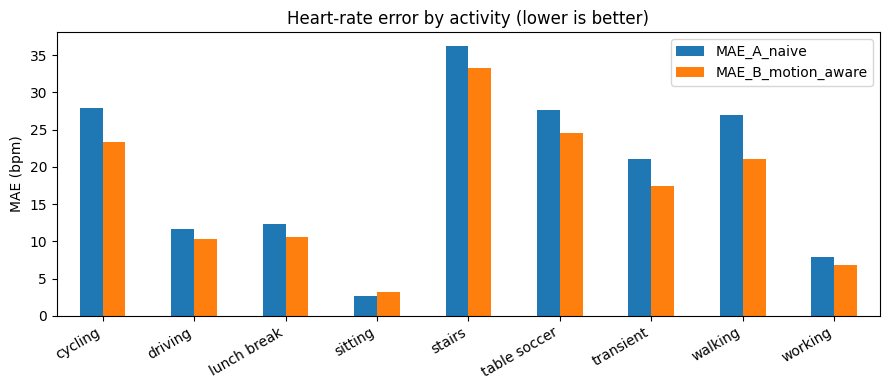

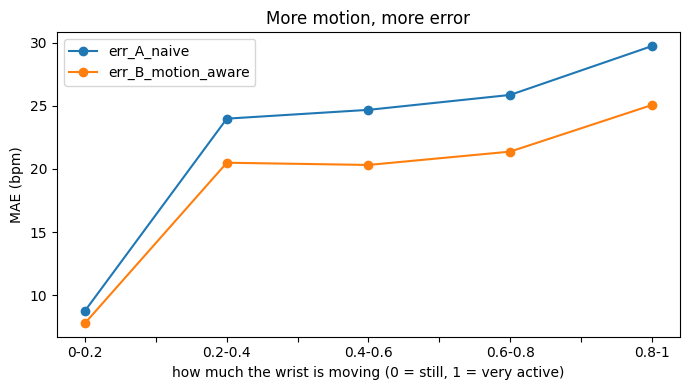

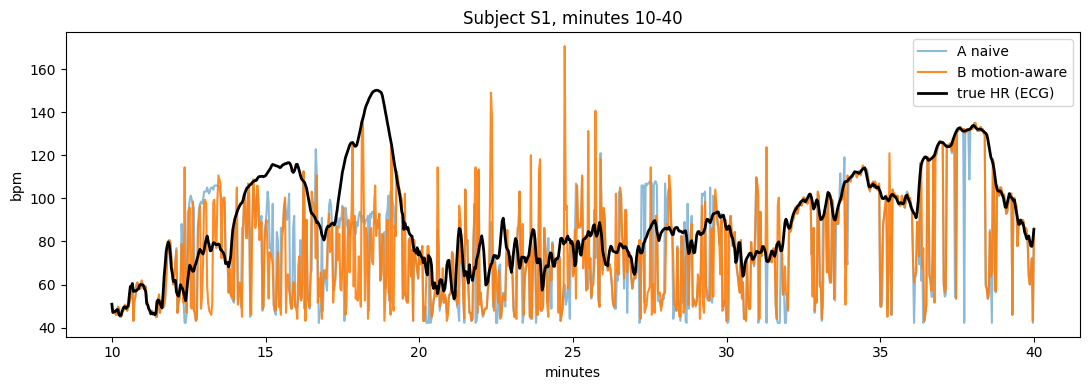

In [17]:
# Chart 1: error per activity
ax = table.drop(index="ALL")[["MAE_" + m for m in METHODS]].plot.bar(figsize=(9, 4))
ax.set_ylabel("MAE (bpm)")
ax.set_title("Heart-rate error by activity (lower is better)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "01_chart_mae_by_activity.png"), dpi=150)
plt.show()

# Chart 2: error vs how much the person is moving
df["motion_bin"] = pd.cut(df["motion_level"], [-0.01, 0.2, 0.4, 0.6, 0.8, 1.0],
                          labels=["0-0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8-1"])
mb = df.groupby("motion_bin", observed=True)[err_cols].mean()
ax = mb.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("how much the wrist is moving (0 = still, 1 = very active)")
ax.set_ylabel("MAE (bpm)"); ax.set_title("More motion, more error")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "01_chart_error_vs_motion.png"), dpi=150)
plt.show()

# Chart 3: one person over time (zoomed), true heart rate drawn last so it is not hidden
sid0 = sorted(PKL)[0]
d0 = df[(df.subject == sid0)]
tmin = d0.window * SHIFT_S / 60
m = (tmin >= 10) & (tmin <= 40)
plt.figure(figsize=(11, 4))
plt.plot(tmin[m], d0.A_naive[m], alpha=.5, label="A naive")
plt.plot(tmin[m], d0.B_motion_aware[m], alpha=.9, label="B motion-aware")
plt.plot(tmin[m], d0.hr_true[m], "k", lw=2, label="true HR (ECG)", zorder=5)
plt.xlabel("minutes"); plt.ylabel("bpm"); plt.title(f"Subject S{sid0}, minutes 10-40")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "01_chart_example_subject.png"), dpi=150)
plt.show()